In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lu_factor, lu_solve

np.random.seed(42)

In [ ]:

import matplotlib as mpl

# ---- STILE PAPER ----
mpl.rcParams.update({

    # Usa font LaTeX (coerente con paper)
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],

    # Dimensioni testo (standard journal)
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,

    # Spessori ottimizzati per stampa
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    # Tick dentro (stile PRL/JCP)
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Griglia molto leggera
    "grid.linestyle": ":",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,

    # Legenda minimale
    "legend.frameon": False,
})

# Test generazione dataset di funzioni

Genero un dataset di funzioni usando "generate_random_f_from_white_noise". In seguito tratto le funzioni generate come vettori e calcolo la matrice di correlazione.

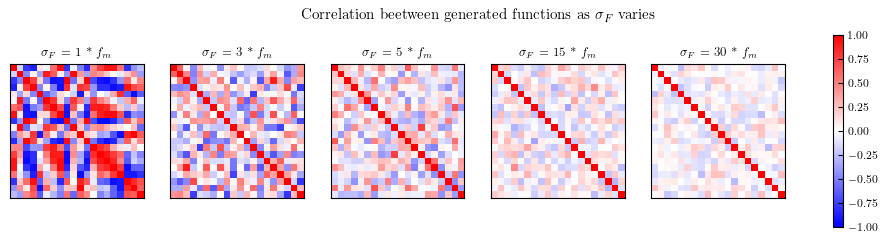

In [ ]:
from generate_f_from_white_noise import *


f_dataset_size = 20
nt = 1000
t_array = np.linspace(0,1,nt)

# Dataset di funzioni dove ogni colonna rappresenta una funzione random su una gliglia temporale
# rappresentata dalle righe. Il dataset è dunque composto da vettori nt dimensionali.
f_dataset = np.zeros(shape=(nt,f_dataset_size))

dt = t_array[1]-t_array[0]   

max_freq = 1/dt
min_freq = 1/(t_array[-1]-t_array[1])

fig, axes = plt.subplots(1,5,figsize=(12.5,2.5))   
index_ax = 0

for sigma_filter_mult in [1,3,5,15,30]:
    
    # NOTE: la sigma del filtro va scelta tenendo conto dello spetto consentito dalla discretizzazione temporale 
    # Io ho trovato che un sigma circa 3-5 volte la frequenza minima produce delle funzione che APPARENTEMENTE sembrano buone,
    # la validità di questa affermazione andrà testata
    sigma_filter = sigma_filter_mult*min_freq
    gaussian_filter = lambda k : np.exp(-(k**2)/(2*sigma_filter**2))

    for index in range(f_dataset_size):
        f_dataset[:,index] = generate_random_f_from_white_noise(t_array, gaussian_filter)

    # Verifico l'indipendenza tra le colonne
    f_corr = np.corrcoef(f_dataset, rowvar=False)

    im = axes[index_ax].imshow(f_corr, cmap='bwr', vmin=-1, vmax=1)
    axes[index_ax].set_title(rf"$\sigma_F$ = {sigma_filter_mult} * $f_m$")
    axes[index_ax].set_xticks([])
    axes[index_ax].set_yticks([])
    index_ax=index_ax+1

fig.colorbar(im, ax=axes.ravel().tolist())
fig.suptitle(r"Correlation beetween generated functions as $\sigma_F$ varies")
plt.savefig("assets/dataset_function_correlations.pdf")
plt.show()

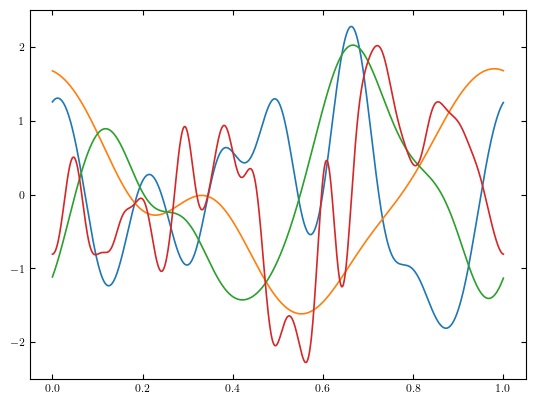

/tmp/ipykernel_18207/2517914145.py:35: UserWarning: Adding colorbar to a different Figure <Figure size 1250x250 with 7 Axes> than <Figure size 640x480 with 1 Axes> which fig.colorbar is called on.
  plt.colorbar(im, ax=axes.ravel().tolist())


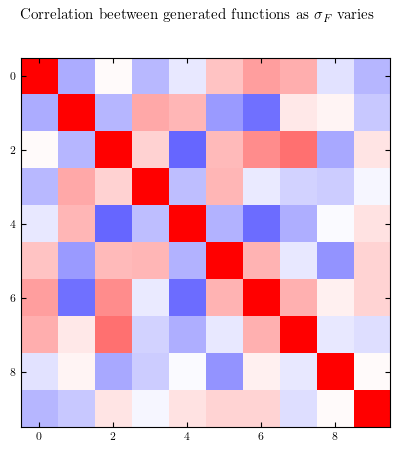

In [ ]:
f_dataset_size = 10
nt = 1000
t_array = np.linspace(0,1,nt)

# Dataset di funzioni dove ogni colonna rappresenta una funzione random su una gliglia temporale
# rappresentata dalle righe. Il dataset è dunque composto da vettori nt dimensionali.
f_dataset = np.zeros(shape=(nt,f_dataset_size))

dt = t_array[1]-t_array[0]   

max_freq = 1/dt
min_freq = 1/(t_array[-1]-t_array[1])

index_ax = 0

eps = 1

for index in range(f_dataset_size):

    sigma_filter = np.random.uniform(low=1,high=10)*min_freq
    gaussian_filter = lambda k : np.exp(-(k**2)/(2*sigma_filter**2))

    f_dataset[:,index] = generate_random_f_from_white_noise(t_array, gaussian_filter)
    index_ax = index_ax + 1

    if index_ax < 5:
        plt.plot(t_array,f_dataset[:,index])
# Verifico l'indipendenza tra le colonne
f_corr = np.corrcoef(f_dataset, rowvar=False)

plt.show()

plt.imshow(f_corr, cmap='bwr', vmin=-1, vmax=1)

plt.colorbar(im, ax=axes.ravel().tolist())
plt.suptitle(r"Correlation beetween generated functions as $\sigma_F$ varies")
plt.savefig("assets/dataset_function_correlations.pdf")
plt.show()

Il filtro passa basso nello spazio di fourier assieme alla continuità delle funzioni introduce una correlazione nel dataset. Il filtro proietta le funzioni su un sottospazio di dimensione sempre più piccola al diminuire della sigma_filtro. Questo si vede dalla diminuzione della correlazione con l'aumento della sigma del filtro gaussiano.

dx: 1.43e-02
dt: 2.00e-01
Errore spaziale: 2.041e-04
Errore temporale: 4.000e-02
hL=20.0
Time scale caratteristica: 2.00e+01
Time scale caratteristica index: 100
r: 4.90e-01


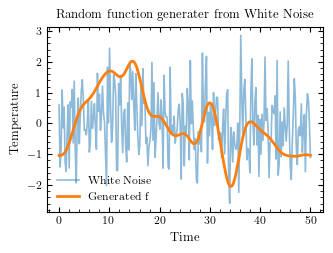

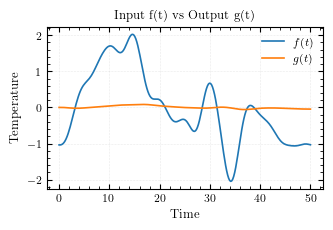

In [ ]:
L = 0.1         # Lunghezza totale
Tf = 50         # Tempo finale
nt = 250        # Griglia temporale

dt = Tf/nt
D = 0.0005
wanted_r = 0.5

dx = np.sqrt(D*dt/wanted_r)
nx = int(L/dx) + 1
dx = L/(nx-1)     

r = D*dt/(dx**2)

print(f"dx: {dx:.2e}")
print(f"dt: {dt:.2e}")

print(f"Errore spaziale: {dx**2:.3e}", )
print(f"Errore temporale: {dt**2:.3e}")

h = 200

print(f"hL={h*L}")
characteristic_diffusion_time_scale = L*L/D
characteristic_diffusion_time_scale_index = int(characteristic_diffusion_time_scale/dt)
print(f"Time scale caratteristica: {characteristic_diffusion_time_scale:.2e}")
print(f"Time scale caratteristica index: {characteristic_diffusion_time_scale_index}")
print(f"r: {r:.2e}")

if(r > 1):
    print("ATTENZIONE: per garantire stabilità numerica e risultati fisicamente corretti è consigliabile avere r minore o uguale a 1.")

x_array = np.linspace(0, L, nx)
t_array = np.linspace(0,Tf,nt)

# Matrici A e B
A = np.zeros((nx, nx))
B = np.zeros((nx, nx))

# Nodi interni
for i in range(1, nx-1):

    A[i, i-1] = -r/2
    A[i, i]   = (1 + r)
    A[i, i+1] = -r/2

    B[i, i-1] = r/2
    B[i, i]   = (1 - r)
    B[i, i+1] = r/2

# Boundary sinistra (Dirichlet)
A[0,0] = 1
B[0,:] = 0

# Boundary destra (Robin)
A[-1, -2] = -2*r
A[-1, -1] = 1 + 2*r*(1+h*dx)

B[-1, -2] = 2*r
B[-1, -1] = 1 - 2*r*(1+h*dx)


lu, piv = lu_factor(A)

T = np.zeros(shape=(nx,nt))

# ----------------------------------------------------------
# NOTE: Sezione da inserire nel loop per la generazione del dataset
# Tutto ciò che precede questa sezione è indipendente dalla simulazione
# sotto la condizione di tenere fissi i parametri di D, h e la discretizzazione spazio-temporale

T[:,0] = 0 # Initial condition

min_freq = 1/(t_array[-1]-t_array[1])

sigma_filter=5*min_freq
gaussian_filter = lambda k : np.exp(-(k**2)/(2*sigma_filter**2))

f = generate_random_f_from_white_noise(t_array, gaussian_filter, verbose=True)
T[0,0] = f[0]

# Questo loop risolve step by step l'equazione implicità
# A*T(n+1) = B*T(n) + b(n+1)
for n in range(1,nt):
    b = B @ T[:,n-1]
    b[0] = f[n] # impongo dirichlet
    T[:,n] = lu_solve((lu, piv), b)

# ----------------------------------------------------------

plt.figure(figsize=(3.4, 2.2))
plt.plot(t_array, T[0,:], label=r"$f(t)$")
plt.plot(t_array, T[-1,:], label=r"$g(t)$")
plt.legend()
plt.minorticks_on()
plt.grid()
plt.xlabel(r"Time")
plt.ylabel(r"Temperature")
plt.tight_layout()
plt.title("Input f(t) vs Output g(t)")
plt.show()

In [ ]:
def forward_simulation(f):
    # NOTE: questa riga va bene solo perchè io assumo che a 
    # t=0 tutto il sistema è termalizzato con l'ambiente.
    # Sennò qui ci va la condizione iniziale
    T = np.zeros((nx, nt))

    T[0,0] = f[0]

    for n in range(1, nt):
        b = B @ T[:,n-1]
        b[0] = f[n]
        T[:,n] = lu_solve((lu, piv), b)

    return T

def loss(f, g_target, lambda_reg : float, cut_index : int = 1):
    
    T = forward_simulation(f)
    g_sim = T[-1, :]
    
    # Termine energetico differenza soluzione trovata e soluzione nota
    misfit = np.linalg.norm(g_sim[:-cut_index] - g_target[:-cut_index])**2

    # Termine fisico per limitare le ampiezze
    #reg = lambda_reg * np.linalg.norm(f[:])**2

    # Termine energetico sulla derivata
    reg = lambda_reg * np.linalg.norm(np.diff(f))**2

    return misfit + reg

Tikonov

In [ ]:
from scipy.optimize import minimize

lambda_reg = 1e-5

# Aggiungo noise gaussiano
noise_level = 0 
T_target = T[-1, :] + noise_level * np.random.randn(nt) 

f_guess = np.zeros(nt)

result = minimize(
    loss,
    f_guess,
    args=(T_target, lambda_reg),
    method='L-BFGS-B',
    options={'maxiter': 50}
)

f_reconstructed = result.x

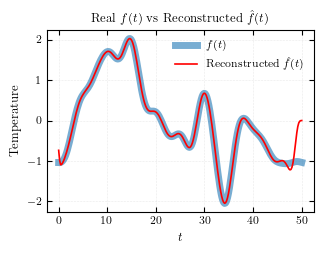

In [ ]:
plt.figure(figsize=(3.4, 2.6))
plt.plot(t_array, T[0,:], label=r"$f(t)$", lw=5, alpha=0.6)
plt.plot(t_array, f_reconstructed, label=r"Reconstructed $\hat{f}(t)$", c="r")
plt.xlabel(r"$t$")
plt.ylabel("Temperature")
plt.title(r"Real $f(t)$ vs Reconstructed $\hat{f}(t)$")
plt.grid()
plt.legend()
plt.tight_layout()
plt.savefig("assets/tikonov_reconstructed_function.pdf")
plt.show()

Calcolo dell'errore cumulativo in t nella ricostruzione. Mi aspetterei di trovare un aumento dell'errore per t vicini al t massimo, dove l'informazione non è ancora ruscita ad diffondere da sinistra a destra. 


Dal grafico sopra però mi sembra che c'è qualcosa nel codice che fissa la ricostruzione a 0 per t = t_f, non ho ancora capito perchè.

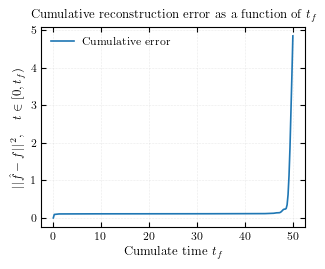

In [ ]:
loss_array = np.zeros(nt)

for n in range(nt):
    loss_array[n] = np.linalg.norm(T[0,0:n] - f_reconstructed[0:n])**2

plt.figure(figsize=(3.4, 2.6))
plt.plot(t_array, loss_array, label="Cumulative error")
plt.ylabel(r"$||\hat{f} - f||^2, \hspace{1em} t \in [0,t_f)$")
plt.xlabel(r"Cumulate time $t_f$")
plt.title(r"Cumulative reconstruction error as a function of $t_f$")
plt.legend()
plt.grid()
plt.show()